In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mihalcearobertmihail/mede-u18-pamap2/readme.pdf
/kaggle/input/datasets/mihalcearobertmihail/mede-u18-pamap2/PAMAP2_Dataset/PAMAP2_Dataset/DataCollectionProtocol.pdf
/kaggle/input/datasets/mihalcearobertmihail/mede-u18-pamap2/PAMAP2_Dataset/PAMAP2_Dataset/DescriptionOfActivities.pdf
/kaggle/input/datasets/mihalcearobertmihail/mede-u18-pamap2/PAMAP2_Dataset/PAMAP2_Dataset/PerformedActivitiesSummary.pdf
/kaggle/input/datasets/mihalcearobertmihail/mede-u18-pamap2/PAMAP2_Dataset/PAMAP2_Dataset/readme.pdf
/kaggle/input/datasets/mihalcearobertmihail/mede-u18-pamap2/PAMAP2_Dataset/PAMAP2_Dataset/subjectInformation.pdf
/kaggle/input/datasets/mihalcearobertmihail/mede-u18-pamap2/PAMAP2_Dataset/PAMAP2_Dataset/Optional/subject101.dat
/kaggle/input/datasets/mihalcearobertmihail/mede-u18-pamap2/PAMAP2_Dataset/PAMAP2_Dataset/Optional/subject105.dat
/kaggle/input/datasets/mihalcearobertmihail/mede-u18-pamap2/PAMAP2_Dataset/PAMAP2_Dataset/Optional/subject106.dat
/kaggle/input/dat

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Paths
MHEALTH_PATH = Path(
    "/kaggle/input/datasets/mihalcearobertmihail/"
    "mede-u18-mhealth/MHEALTHDATASET"
)

PAMAP2_PATH = Path(
    "/kaggle/input/datasets/mihalcearobertmihail/"
    "mede-u18-pamap2/PAMAP2_Dataset/PAMAP2_Dataset"
)

# Files
mhealth_files = sorted(MHEALTH_PATH.glob("mHealth_subject*.log"))
pamap2_files = sorted((PAMAP2_PATH / "Protocol").glob("subject*.dat"))

print("MHEALTH")
print("Number of subjects:", len(mhealth_files))
print("Example:", mhealth_files[0].name)

print("\nPAMAP2")
print("Number of subjects:", len(pamap2_files))
print("Example:", pamap2_files[0].name)

MHEALTH
Number of subjects: 10
Example: mHealth_subject1.log

PAMAP2
Number of subjects: 9
Example: subject101.dat


In [3]:
# Load one subject from each dataset

mhealth_sample = pd.read_csv(
    mhealth_files[0],
    sep=r"\s+",
    header=None
)

pamap2_sample = pd.read_csv(
    pamap2_files[0],
    sep=r"\s+",
    header=None
)

print("MHEALTH shape:", mhealth_sample.shape)
print("PAMAP2 shape:", pamap2_sample.shape)

print("\nMHEALTH sample:")
display(mhealth_sample.head())

print("\nPAMAP2 sample:")
display(pamap2_sample.head())

MHEALTH shape: (161280, 24)
PAMAP2 shape: (376417, 54)

MHEALTH sample:


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
0,-9.8184,0.009971,0.29563,0.004186,0.004186,2.1849,-9.6967,0.63077,0.103900,-0.84053,...,-8.6499,-4.5781,0.187760,-0.44902,-1.0103,0.034483,-2.35000,-1.610200,-0.030899,0
1,-9.8489,0.524040,0.37348,0.004186,0.016745,2.3876,-9.5080,0.68389,0.085343,-0.83865,...,-8.6275,-4.3198,0.023595,-0.44902,-1.0103,0.034483,-2.16320,-0.882540,0.326570,0
2,-9.6602,0.181850,0.43742,0.016745,0.037677,2.4086,-9.5674,0.68113,0.085343,-0.83865,...,-8.5055,-4.2772,0.275720,-0.44902,-1.0103,0.034483,-1.61750,-0.165620,-0.030693,0
3,-9.6507,0.214220,0.24033,0.079540,0.117220,2.1814,-9.4301,0.55031,0.085343,-0.83865,...,-8.6279,-4.3163,0.367520,-0.45686,-1.0082,0.025862,-1.07710,0.006945,-0.382620,0
4,-9.7030,0.303890,0.31156,0.221870,0.205130,2.4173,-9.3889,0.71098,0.085343,-0.83865,...,-8.7008,-4.1459,0.407290,-0.45686,-1.0082,0.025862,-0.53684,0.175900,-1.095500,0



PAMAP2 sample:


,0,1,2,3,4,5,6,7,8,9,...,44,45,46,47,48,49,50,51,52,53
0,8.38,0,104.0,30.0,2.37223,8.60074,3.51048,2.43954,8.76165,3.35465,...,0.008300,0.009250,-0.017580,-61.1888,-38.9599,-58.1438,1.0,0.0,0.0,0.0
1,8.39,0,NaN,30.0,2.18837,8.56560,3.66179,2.39494,8.55081,3.64207,...,-0.006577,-0.004638,0.000368,-59.8479,-38.8919,-58.5253,1.0,0.0,0.0,0.0
2,8.40,0,NaN,30.0,2.37357,8.60107,3.54898,2.30514,8.53644,3.73280,...,0.003014,0.000148,0.022495,-60.7361,-39.4138,-58.3999,1.0,0.0,0.0,0.0
3,8.41,0,NaN,30.0,2.07473,8.52853,3.66021,2.33528,8.53622,3.73277,...,0.003175,-0.020301,0.011275,-60.4091,-38.7635,-58.3956,1.0,0.0,0.0,0.0
4,8.42,0,NaN,30.0,2.22936,8.83122,3.70000,2.23055,8.59741,3.76295,...,0.012698,-0.014303,-0.002823,-61.5199,-39.3879,-58.2694,1.0,0.0,0.0,0.0


In [4]:
mhealth_columns = [
    "chest_acc_x",
    "chest_acc_y",
    "chest_acc_z",
    "ecg_lead_1",
    "ecg_lead_2",

    "ankle_acc_x",
    "ankle_acc_y",
    "ankle_acc_z",
    "ankle_gyro_x",
    "ankle_gyro_y",
    "ankle_gyro_z",
    "ankle_mag_x",
    "ankle_mag_y",
    "ankle_mag_z",

    "arm_acc_x",
    "arm_acc_y",
    "arm_acc_z",
    "arm_gyro_x",
    "arm_gyro_y",
    "arm_gyro_z",
    "arm_mag_x",
    "arm_mag_y",
    "arm_mag_z",

    "activity"
]

mhealth_sample.columns = mhealth_columns

display(mhealth_sample.head())

,chest_acc_x,chest_acc_y,chest_acc_z,ecg_lead_1,ecg_lead_2,ankle_acc_x,ankle_acc_y,ankle_acc_z,ankle_gyro_x,ankle_gyro_y,...,arm_acc_x,arm_acc_y,arm_acc_z,arm_gyro_x,arm_gyro_y,arm_gyro_z,arm_mag_x,arm_mag_y,arm_mag_z,activity
0,-9.8184,0.009971,0.29563,0.004186,0.004186,2.1849,-9.6967,0.63077,0.103900,-0.84053,...,-8.6499,-4.5781,0.187760,-0.44902,-1.0103,0.034483,-2.35000,-1.610200,-0.030899,0
1,-9.8489,0.524040,0.37348,0.004186,0.016745,2.3876,-9.5080,0.68389,0.085343,-0.83865,...,-8.6275,-4.3198,0.023595,-0.44902,-1.0103,0.034483,-2.16320,-0.882540,0.326570,0
2,-9.6602,0.181850,0.43742,0.016745,0.037677,2.4086,-9.5674,0.68113,0.085343,-0.83865,...,-8.5055,-4.2772,0.275720,-0.44902,-1.0103,0.034483,-1.61750,-0.165620,-0.030693,0
3,-9.6507,0.214220,0.24033,0.079540,0.117220,2.1814,-9.4301,0.55031,0.085343,-0.83865,...,-8.6279,-4.3163,0.367520,-0.45686,-1.0082,0.025862,-1.07710,0.006945,-0.382620,0
4,-9.7030,0.303890,0.31156,0.221870,0.205130,2.4173,-9.3889,0.71098,0.085343,-0.83865,...,-8.7008,-4.1459,0.407290,-0.45686,-1.0082,0.025862,-0.53684,0.175900,-1.095500,0


In [5]:
print("Number of columns:", len(mhealth_sample.columns))

print("\nActivity labels:")
print(
    mhealth_sample["activity"]
    .value_counts()
    .sort_index()
)

print("\nMissing values:")
print(mhealth_sample.isna().sum())

Number of columns: 24

Activity labels:
activity
0     126106
1       3072
2       3072
3       3072
4       3072
5       3072
6       3072
7       3072
8       3379
9       3072
10      3072
11      3072
12      1075
Name: count, dtype: int64

Missing values:
chest_acc_x     0
chest_acc_y     0
chest_acc_z     0
ecg_lead_1      0
ecg_lead_2      0
ankle_acc_x     0
ankle_acc_y     0
ankle_acc_z     0
ankle_gyro_x    0
ankle_gyro_y    0
ankle_gyro_z    0
ankle_mag_x     0
ankle_mag_y     0
ankle_mag_z     0
arm_acc_x       0
arm_acc_y       0
arm_acc_z       0
arm_gyro_x      0
arm_gyro_y      0
arm_gyro_z      0
arm_mag_x       0
arm_mag_y       0
arm_mag_z       0
activity        0
dtype: int64


In [6]:
imu_columns = [
    "temperature",
    "acc16_x", "acc16_y", "acc16_z",
    "acc6_x", "acc6_y", "acc6_z",
    "gyro_x", "gyro_y", "gyro_z",
    "mag_x", "mag_y", "mag_z",
    "orientation_1", "orientation_2",
    "orientation_3", "orientation_4"
]

pamap2_columns = [
    "timestamp",
    "activity_id",
    "heart_rate"
]

for location in ["hand", "chest", "ankle"]:
    pamap2_columns += [
        f"{location}_{column}"
        for column in imu_columns
    ]

print("Number of column names:", len(pamap2_columns))

pamap2_sample.columns = pamap2_columns

display(pamap2_sample.head())

Number of column names: 54


,timestamp,activity_id,heart_rate,hand_temperature,hand_acc16_x,hand_acc16_y,hand_acc16_z,hand_acc6_x,hand_acc6_y,hand_acc6_z,...,ankle_gyro_x,ankle_gyro_y,ankle_gyro_z,ankle_mag_x,ankle_mag_y,ankle_mag_z,ankle_orientation_1,ankle_orientation_2,ankle_orientation_3,ankle_orientation_4
0,8.38,0,104.0,30.0,2.37223,8.60074,3.51048,2.43954,8.76165,3.35465,...,0.008300,0.009250,-0.017580,-61.1888,-38.9599,-58.1438,1.0,0.0,0.0,0.0
1,8.39,0,NaN,30.0,2.18837,8.56560,3.66179,2.39494,8.55081,3.64207,...,-0.006577,-0.004638,0.000368,-59.8479,-38.8919,-58.5253,1.0,0.0,0.0,0.0
2,8.40,0,NaN,30.0,2.37357,8.60107,3.54898,2.30514,8.53644,3.73280,...,0.003014,0.000148,0.022495,-60.7361,-39.4138,-58.3999,1.0,0.0,0.0,0.0
3,8.41,0,NaN,30.0,2.07473,8.52853,3.66021,2.33528,8.53622,3.73277,...,0.003175,-0.020301,0.011275,-60.4091,-38.7635,-58.3956,1.0,0.0,0.0,0.0
4,8.42,0,NaN,30.0,2.22936,8.83122,3.70000,2.23055,8.59741,3.76295,...,0.012698,-0.014303,-0.002823,-61.5199,-39.3879,-58.2694,1.0,0.0,0.0,0.0


In [7]:
print("Shape:", pamap2_sample.shape)

print("\nActivity IDs:")
print(
    pamap2_sample["activity_id"]
    .value_counts()
    .sort_index()
)

print("\nHeart rate:")
print(pamap2_sample["heart_rate"].describe())

print("\nMissing heart rate values:")
print(pamap2_sample["heart_rate"].isna().sum())

print("\nMissing heart rate (%):")
print(
    round(
        pamap2_sample["heart_rate"].isna().mean() * 100,
        2
    ),
    "%"
)

Shape: (376417, 54)

Activity IDs:
activity_id
0     126460
1      27187
2      23480
3      21717
4      22253
5      21265
6      23575
7      20265
12     15890
13     14899
16     22941
17     23573
24     12912
Name: count, dtype: int64

Heart rate:
count    34389.000000
mean       124.135479
std         24.000340
min         78.000000
25%        104.000000
50%        125.000000
75%        136.000000
max        183.000000
Name: heart_rate, dtype: float64

Missing heart rate values:
342028

Missing heart rate (%):
90.86 %


## Loading pipeline – all subjects

The following pipeline loads all subjects from PAMAP2 and MHEALTH
and adds a subject identifier to each observation.

In [8]:
# Load all PAMAP2 subjects

pamap2_data = []

for file in pamap2_files:
    df = pd.read_csv(
        file,
        sep=r"\s+",
        header=None,
        names=pamap2_columns
    )

    # subject101.dat -> 101
    subject_id = file.stem.replace("subject", "")
    df["subject_id"] = subject_id

    pamap2_data.append(df)

pamap2 = pd.concat(pamap2_data, ignore_index=True)

print("PAMAP2 successfully loaded")
print("Subjects:", pamap2["subject_id"].nunique())
print("Rows:", len(pamap2))
print("Columns:", pamap2.shape[1])
print("Activities:", sorted(pamap2["activity_id"].unique()))

PAMAP2 successfully loaded
Subjects: 9
Rows: 2872533
Columns: 55
Activities: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(12), np.int64(13), np.int64(16), np.int64(17), np.int64(24)]


In [9]:
# Load all MHEALTH subjects

mhealth_data = []

for file in mhealth_files:
    df = pd.read_csv(
        file,
        sep=r"\s+",
        header=None,
        names=mhealth_columns
    )

    # mHealth_subject1.log -> 1
    subject_id = file.stem.replace("mHealth_subject", "")
    df["subject_id"] = subject_id

    mhealth_data.append(df)

mhealth = pd.concat(mhealth_data, ignore_index=True)

print("MHEALTH successfully loaded")
print("Subjects:", mhealth["subject_id"].nunique())
print("Rows:", len(mhealth))
print("Columns:", mhealth.shape[1])
print("Activities:", sorted(mhealth["activity"].unique()))

MHEALTH successfully loaded
Subjects: 10
Rows: 1215745
Columns: 25
Activities: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


In [10]:
# Loading pipeline summary

summary = pd.DataFrame({
    "Dataset": ["PAMAP2", "MHEALTH"],
    "Files loaded": [len(pamap2_files), len(mhealth_files)],
    "Subjects": [
        pamap2["subject_id"].nunique(),
        mhealth["subject_id"].nunique()
    ],
    "Rows": [
        len(pamap2),
        len(mhealth)
    ],
    "Columns": [
        pamap2.shape[1],
        mhealth.shape[1]
    ],
    "Activities": [
        pamap2["activity_id"].nunique(),
        mhealth["activity"].nunique()
    ]
})

display(summary)

,Dataset,Files loaded,Subjects,Rows,Columns,Activities
0,PAMAP2,9,9,2872533,55,13
1,MHEALTH,10,10,1215745,25,13


## CP1 – Temporal alignment and coverage report

The two datasets are aligned independently because they contain different participants.
The common analysis unit is person × temporal window.

For CP1, the goal is to align motion and cardiac information in time,
without extracting the final feature matrix yet.

In [11]:
%whos DataFrame

Variable         Type         Data/Info
---------------------------------------
df               DataFrame            chest_acc_x  ches<...>135168 rows x 25 columns]
mhealth          DataFrame             chest_acc_x  che<...>215745 rows x 25 columns]
mhealth_sample   DataFrame            chest_acc_x  ches<...>161280 rows x 24 columns]
pamap2           DataFrame             timestamp  activ<...>872533 rows x 55 columns]
pamap2_sample    DataFrame            timestamp  activi<...>376417 rows x 54 columns]
summary          DataFrame       Dataset  Files loaded <...>5745       25          13


In [12]:
print(pamap2.columns.tolist())

['timestamp', 'activity_id', 'heart_rate', 'hand_temperature', 'hand_acc16_x', 'hand_acc16_y', 'hand_acc16_z', 'hand_acc6_x', 'hand_acc6_y', 'hand_acc6_z', 'hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z', 'hand_mag_x', 'hand_mag_y', 'hand_mag_z', 'hand_orientation_1', 'hand_orientation_2', 'hand_orientation_3', 'hand_orientation_4', 'chest_temperature', 'chest_acc16_x', 'chest_acc16_y', 'chest_acc16_z', 'chest_acc6_x', 'chest_acc6_y', 'chest_acc6_z', 'chest_gyro_x', 'chest_gyro_y', 'chest_gyro_z', 'chest_mag_x', 'chest_mag_y', 'chest_mag_z', 'chest_orientation_1', 'chest_orientation_2', 'chest_orientation_3', 'chest_orientation_4', 'ankle_temperature', 'ankle_acc16_x', 'ankle_acc16_y', 'ankle_acc16_z', 'ankle_acc6_x', 'ankle_acc6_y', 'ankle_acc6_z', 'ankle_gyro_x', 'ankle_gyro_y', 'ankle_gyro_z', 'ankle_mag_x', 'ankle_mag_y', 'ankle_mag_z', 'ankle_orientation_1', 'ankle_orientation_2', 'ankle_orientation_3', 'ankle_orientation_4', 'subject_id']


In [13]:
# CP1 - PAMAP2 temporal alignment

WINDOW_SECONDS = 5

pamap2_aligned = pamap2.copy()

# Activity 0 = transient / undefined activity -> exclude
pamap2_aligned = pamap2_aligned[
    pamap2_aligned["activity_id"] != 0
].copy()

# Create a 5-second temporal grid for each subject
pamap2_aligned["window_id"] = (
    pamap2_aligned["timestamp"] // WINDOW_SECONDS
).astype(int)

# Interpolate heart rate independently for each subject
pamap2_aligned["heart_rate_aligned"] = (
    pamap2_aligned
    .groupby("subject_id")["heart_rate"]
    .transform(lambda x: x.interpolate(limit_direction="both"))
)

print("PAMAP2 rows after removing activity 0:", len(pamap2_aligned))

print(
    "Missing HR before alignment:",
    f"{pamap2_aligned['heart_rate'].isna().mean() * 100:.2f}%"
)

print(
    "Missing HR after alignment:",
    f"{pamap2_aligned['heart_rate_aligned'].isna().mean() * 100:.2f}%"
)

pamap2_aligned[
    [
        "subject_id",
        "timestamp",
        "window_id",
        "activity_id",
        "heart_rate",
        "heart_rate_aligned"
    ]
].head(15)

PAMAP2 rows after removing activity 0: 1942872
Missing HR before alignment: 90.87%
Missing HR after alignment: 0.00%


,subject_id,timestamp,window_id,activity_id,heart_rate,heart_rate_aligned
2928,101,37.66,7,1,NaN,100.0
2929,101,37.67,7,1,NaN,100.0
2930,101,37.68,7,1,NaN,100.0
2931,101,37.69,7,1,NaN,100.0
2932,101,37.70,7,1,100.0,100.0
2933,101,37.71,7,1,NaN,100.0
2934,101,37.72,7,1,NaN,100.0
2935,101,37.73,7,1,NaN,100.0
2936,101,37.74,7,1,NaN,100.0
2937,101,37.75,7,1,NaN,100.0


In [14]:
# CP1 - PAMAP2 aligned window table

pamap2_windows = (
    pamap2_aligned
    .groupby(["subject_id", "window_id"])
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        activity_id=("activity_id", lambda x: x.mode().iloc[0]),
        imu_samples=("timestamp", "size"),
        hr_raw_samples=("heart_rate", "count"),
        heart_rate=("heart_rate_aligned", "mean")
    )
    .reset_index()
)

# Coverage: a valid aligned window contains motion samples
# and cardiac information after temporal alignment
pamap2_windows["has_motion"] = pamap2_windows["imu_samples"] > 0
pamap2_windows["has_cardiac"] = pamap2_windows["heart_rate"].notna()
pamap2_windows["complete_multimodal"] = (
    pamap2_windows["has_motion"] &
    pamap2_windows["has_cardiac"]
)

print("PAMAP2 aligned table")
print("Unit: subject × 5-second window")
print("Total windows:", len(pamap2_windows))
print(
    "Complete multimodal windows:",
    pamap2_windows["complete_multimodal"].sum()
)
print(
    "Coverage:",
    f"{pamap2_windows['complete_multimodal'].mean() * 100:.2f}%"
)

pamap2_windows.head(10)

PAMAP2 aligned table
Unit: subject × 5-second window
Total windows: 3974
Complete multimodal windows: 3974
Coverage: 100.00%


,subject_id,window_id,start_time,end_time,activity_id,imu_samples,hr_raw_samples,heart_rate,has_motion,has_cardiac,complete_multimodal
0,101,7,37.66,39.99,1,234,21,100.884615,True,True,True
1,101,8,40.00,44.99,1,500,46,102.000000,True,True,True
2,101,9,45.00,49.99,1,500,46,102.738000,True,True,True
3,101,10,50.00,54.99,1,500,46,105.416000,True,True,True
4,101,11,55.00,59.99,1,500,45,106.264000,True,True,True
5,101,12,60.00,64.99,1,500,46,103.554000,True,True,True
6,101,13,65.00,69.99,1,500,46,99.924000,True,True,True
7,101,14,70.00,74.99,1,500,45,96.506000,True,True,True
8,101,15,75.00,79.99,1,500,46,94.318000,True,True,True
9,101,16,80.00,84.99,1,500,46,93.194000,True,True,True


In [15]:
print(mhealth.columns.tolist())

['chest_acc_x', 'chest_acc_y', 'chest_acc_z', 'ecg_lead_1', 'ecg_lead_2', 'ankle_acc_x', 'ankle_acc_y', 'ankle_acc_z', 'ankle_gyro_x', 'ankle_gyro_y', 'ankle_gyro_z', 'ankle_mag_x', 'ankle_mag_y', 'ankle_mag_z', 'arm_acc_x', 'arm_acc_y', 'arm_acc_z', 'arm_gyro_x', 'arm_gyro_y', 'arm_gyro_z', 'arm_mag_x', 'arm_mag_y', 'arm_mag_z', 'activity', 'subject_id']


In [16]:
# CP1 - MHEALTH temporal alignment

WINDOW_SECONDS = 5
MHEALTH_HZ = 50
SAMPLES_PER_WINDOW = WINDOW_SECONDS * MHEALTH_HZ  # 250

mhealth_aligned = mhealth.copy()

# Activity 0 = null / transition periods -> exclude
mhealth_aligned = mhealth_aligned[
    mhealth_aligned["activity"] != 0
].copy()

# Rebuild sample position independently for each subject
mhealth_aligned["sample_id"] = (
    mhealth_aligned
    .groupby("subject_id")
    .cumcount()
)

# Temporal grid: 250 samples = 5 seconds at 50 Hz
mhealth_aligned["window_id"] = (
    mhealth_aligned["sample_id"] // SAMPLES_PER_WINDOW
).astype(int)

# Check availability of motion and ECG at sample level
motion_cols = ["chest_acc_x", "chest_acc_y", "chest_acc_z"]
ecg_cols = ["ecg_lead_1", "ecg_lead_2"]

mhealth_aligned["motion_valid"] = (
    mhealth_aligned[motion_cols].notna().all(axis=1)
)

mhealth_aligned["ecg_valid"] = (
    mhealth_aligned[ecg_cols].notna().all(axis=1)
)

print("MHEALTH rows after removing activity 0:", len(mhealth_aligned))
print(
    "Missing motion samples:",
    f"{(1 - mhealth_aligned['motion_valid'].mean()) * 100:.2f}%"
)
print(
    "Missing ECG samples:",
    f"{(1 - mhealth_aligned['ecg_valid'].mean()) * 100:.2f}%"
)

MHEALTH rows after removing activity 0: 343195
Missing motion samples: 0.00%
Missing ECG samples: 0.00%


In [17]:
# Build aligned table: one row = subject × 5-second window

mhealth_windows = (
    mhealth_aligned
    .groupby(["subject_id", "window_id"])
    .agg(
        activity=("activity", lambda x: x.mode().iloc[0]),
        samples=("sample_id", "size"),
        motion_samples=("motion_valid", "sum"),
        ecg_samples=("ecg_valid", "sum")
    )
    .reset_index()
)

# A full 5-second MHEALTH window contains 250 samples
mhealth_windows["full_window"] = (
    mhealth_windows["samples"] == SAMPLES_PER_WINDOW
)

mhealth_windows["complete_multimodal"] = (
    (mhealth_windows["motion_samples"] == mhealth_windows["samples"]) &
    (mhealth_windows["ecg_samples"] == mhealth_windows["samples"])
)

print("\nMHEALTH aligned table")
print("Unit: subject × 5-second window")
print("Total windows:", len(mhealth_windows))
print("Full 5-second windows:", mhealth_windows["full_window"].sum())
print(
    "Complete multimodal windows:",
    mhealth_windows["complete_multimodal"].sum()
)
print(
    "Multimodal coverage:",
    f"{mhealth_windows['complete_multimodal'].mean() * 100:.2f}%"
)

mhealth_windows.head(10)


MHEALTH aligned table
Unit: subject × 5-second window
Total windows: 1378
Full 5-second windows: 1368
Complete multimodal windows: 1378
Multimodal coverage: 100.00%


,subject_id,window_id,activity,samples,motion_samples,ecg_samples,full_window,complete_multimodal
0,1,0,1,250,250,250,True,True
1,1,1,1,250,250,250,True,True
2,1,2,1,250,250,250,True,True
3,1,3,1,250,250,250,True,True
4,1,4,1,250,250,250,True,True
5,1,5,1,250,250,250,True,True
6,1,6,1,250,250,250,True,True
7,1,7,1,250,250,250,True,True
8,1,8,1,250,250,250,True,True
9,1,9,1,250,250,250,True,True


In [18]:
# CP1 - Final alignment coverage report

# PAMAP2: full 5-second window = 500 IMU samples
pamap2_windows["full_window"] = (
    pamap2_windows["imu_samples"] == 500
)

pamap2_valid = pamap2_windows[
    pamap2_windows["full_window"] &
    pamap2_windows["complete_multimodal"]
].copy()

# MHEALTH: full 5-second window = 250 samples
mhealth_valid = mhealth_windows[
    mhealth_windows["full_window"] &
    mhealth_windows["complete_multimodal"]
].copy()

coverage_report = pd.DataFrame({
    "Dataset": ["PAMAP2", "MHEALTH"],
    "Subjects": [
        pamap2_valid["subject_id"].nunique(),
        mhealth_valid["subject_id"].nunique()
    ],
    "Total windows": [
        len(pamap2_windows),
        len(mhealth_windows)
    ],
    "Full 5s windows": [
        pamap2_windows["full_window"].sum(),
        mhealth_windows["full_window"].sum()
    ],
    "Final aligned windows": [
        len(pamap2_valid),
        len(mhealth_valid)
    ],
    "Coverage (%)": [
        len(pamap2_valid) / len(pamap2_windows) * 100,
        len(mhealth_valid) / len(mhealth_windows) * 100
    ]
})

coverage_report["Coverage (%)"] = (
    coverage_report["Coverage (%)"].round(2)
)

coverage_report

,Dataset,Subjects,Total windows,Full 5s windows,Final aligned windows,Coverage (%)
0,PAMAP2,9,3974,3805,3805,95.75
1,MHEALTH,10,1378,1368,1368,99.27


In [19]:
# CP1 - Examples of the final aligned unit × time tables

pamap2_cp1_table = pamap2_valid[
    [
        "subject_id",
        "window_id",
        "start_time",
        "end_time",
        "activity_id",
        "imu_samples",
        "hr_raw_samples",
        "heart_rate"
    ]
].copy()

mhealth_cp1_table = mhealth_valid[
    [
        "subject_id",
        "window_id",
        "activity",
        "samples",
        "motion_samples",
        "ecg_samples"
    ]
].copy()

print("PAMAP2 – aligned table (one row = subject × 5 s)")
display(pamap2_cp1_table.head())

print("\nMHEALTH – aligned table (one row = subject × 5 s)")
display(mhealth_cp1_table.head())

PAMAP2 – aligned table (one row = subject × 5 s)


,subject_id,window_id,start_time,end_time,activity_id,imu_samples,hr_raw_samples,heart_rate
1,101,8,40.0,44.99,1,500,46,102.000
2,101,9,45.0,49.99,1,500,46,102.738
3,101,10,50.0,54.99,1,500,46,105.416
4,101,11,55.0,59.99,1,500,45,106.264
5,101,12,60.0,64.99,1,500,46,103.554



MHEALTH – aligned table (one row = subject × 5 s)


,subject_id,window_id,activity,samples,motion_samples,ecg_samples
0,1,0,1,250,250,250
1,1,1,1,250,250,250
2,1,2,1,250,250,250
3,1,3,1,250,250,250
4,1,4,1,250,250,250


In [20]:
# CP1 - Final aligned tables
# One row = subject × 5-second window

pamap2_cp1_table = pamap2_valid[
    [
        "subject_id",
        "window_id",
        "start_time",
        "end_time",
        "activity_id",
        "imu_samples",
        "hr_raw_samples",
        "heart_rate"
    ]
].copy()

mhealth_cp1_table = mhealth_valid[
    [
        "subject_id",
        "window_id",
        "activity",
        "samples",
        "motion_samples",
        "ecg_samples"
    ]
].copy()

print("PAMAP2 – aligned table (one row = subject × 5 s)")
display(pamap2_cp1_table.head())

print("\nMHEALTH – aligned table (one row = subject × 5 s)")
display(mhealth_cp1_table.head())

PAMAP2 – aligned table (one row = subject × 5 s)


,subject_id,window_id,start_time,end_time,activity_id,imu_samples,hr_raw_samples,heart_rate
1,101,8,40.0,44.99,1,500,46,102.000
2,101,9,45.0,49.99,1,500,46,102.738
3,101,10,50.0,54.99,1,500,46,105.416
4,101,11,55.0,59.99,1,500,45,106.264
5,101,12,60.0,64.99,1,500,46,103.554



MHEALTH – aligned table (one row = subject × 5 s)


,subject_id,window_id,activity,samples,motion_samples,ecg_samples
0,1,0,1,250,250,250
1,1,1,1,250,250,250
2,1,2,1,250,250,250
3,1,3,1,250,250,250
4,1,4,1,250,250,250


# CP2 – Feature Extraction and Linear Representation

## 1. Temporal alignment validation
## 2. Feature extraction by modality
## 3. Feature matrix X
## 4. Scaling and descriptive statistics
## 5. PCA and experimental protocol

In [21]:
# CP2 - Verify data and alignment outputs from CP1

print("PAMAP2 original:", pamap2.shape)
print("MHEALTH original:", mhealth.shape)

print("\nPAMAP2 valid windows:", len(pamap2_valid))
print("MHEALTH valid windows:", len(mhealth_valid))

print("\nPAMAP2 columns:")
print(pamap2.columns.tolist())

print("\nMHEALTH columns:")
print(mhealth.columns.tolist())

PAMAP2 original: (2872533, 55)
MHEALTH original: (1215745, 25)

PAMAP2 valid windows: 3805
MHEALTH valid windows: 1368

PAMAP2 columns:
['timestamp', 'activity_id', 'heart_rate', 'hand_temperature', 'hand_acc16_x', 'hand_acc16_y', 'hand_acc16_z', 'hand_acc6_x', 'hand_acc6_y', 'hand_acc6_z', 'hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z', 'hand_mag_x', 'hand_mag_y', 'hand_mag_z', 'hand_orientation_1', 'hand_orientation_2', 'hand_orientation_3', 'hand_orientation_4', 'chest_temperature', 'chest_acc16_x', 'chest_acc16_y', 'chest_acc16_z', 'chest_acc6_x', 'chest_acc6_y', 'chest_acc6_z', 'chest_gyro_x', 'chest_gyro_y', 'chest_gyro_z', 'chest_mag_x', 'chest_mag_y', 'chest_mag_z', 'chest_orientation_1', 'chest_orientation_2', 'chest_orientation_3', 'chest_orientation_4', 'ankle_temperature', 'ankle_acc16_x', 'ankle_acc16_y', 'ankle_acc16_z', 'ankle_acc6_x', 'ankle_acc6_y', 'ankle_acc6_z', 'ankle_gyro_x', 'ankle_gyro_y', 'ankle_gyro_z', 'ankle_mag_x', 'ankle_mag_y', 'ankle_mag_z', 'ankle_orientat

In [22]:
# CP2 - Correct MHEALTH temporal windows

WINDOW_SECONDS = 5
MHEALTH_HZ = 50
SAMPLES_PER_WINDOW = WINDOW_SECONDS * MHEALTH_HZ

mhealth_corrected = mhealth.copy()

# Preserve the original sample position for each subject
mhealth_corrected["sample_id"] = (
    mhealth_corrected.groupby("subject_id").cumcount()
)

# Construct windows before removing activity 0
mhealth_corrected["window_id"] = (
    mhealth_corrected["sample_id"] // SAMPLES_PER_WINDOW
)

# Remove unlabeled / transition samples
mhealth_corrected = mhealth_corrected[
    mhealth_corrected["activity"] != 0
].copy()

# Count samples in each window
mhealth_window_counts = (
    mhealth_corrected
    .groupby(["subject_id", "window_id"])
    .size()
    .reset_index(name="samples")
)

# Keep only full 5-second windows
mhealth_full_windows = mhealth_window_counts[
    mhealth_window_counts["samples"] == SAMPLES_PER_WINDOW
].copy()

print("Previous CP1 valid windows:", len(mhealth_valid))
print("Corrected full windows:", len(mhealth_full_windows))
print("Subjects retained:", mhealth_full_windows["subject_id"].nunique())

display(mhealth_full_windows.head(10))

Previous CP1 valid windows: 1368
Corrected full windows: 1251
Subjects retained: 10


,subject_id,window_id,samples
1,1,27,250
2,1,28,250
3,1,29,250
4,1,30,250
5,1,31,250
6,1,32,250
7,1,33,250
8,1,34,250
9,1,35,250
10,1,36,250


In [23]:

# CP2 - Validate PAMAP2 temporal windows

import numpy as np
import pandas as pd

pamap2_check = pamap2.copy()

WINDOW_SECONDS = 5
EXPECTED_SAMPLES = 500  # PAMAP2 IMU: 100 Hz

pamap2_check = pamap2_check[
    pamap2_check["activity_id"] != 0
].copy()

# Keep original timestamps when assigning windows
pamap2_check["window_id"] = (
    np.floor(pamap2_check["timestamp"] / WINDOW_SECONDS)
    .astype(int)
)

pamap2_window_check = (
    pamap2_check
    .groupby(["subject_id", "window_id"])
    .agg(
        samples=("timestamp", "size"),
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        activities=("activity_id", "nunique")
    )
    .reset_index()
)

# A valid window must have all samples and one activity
pamap2_window_check["valid"] = (
    (pamap2_window_check["samples"] == EXPECTED_SAMPLES)
    & (pamap2_window_check["activities"] == 1)
)

pamap2_full_windows = pamap2_window_check[
    pamap2_window_check["valid"]
].copy()

print("Total candidate windows:", len(pamap2_window_check))
print("Valid 5-second windows:", len(pamap2_full_windows))
print("Subjects retained:", pamap2_full_windows["subject_id"].nunique())
print(
    "Coverage:",
    f"{len(pamap2_full_windows) / len(pamap2_window_check) * 100:.2f}%"
)

display(pamap2_full_windows.head(10))


Total candidate windows: 3974
Valid 5-second windows: 3783
Subjects retained: 9
Coverage: 95.19%


,subject_id,window_id,samples,start_time,end_time,activities,valid
1,101,8,500,40.0,44.99,1,True
2,101,9,500,45.0,49.99,1,True
3,101,10,500,50.0,54.99,1,True
4,101,11,500,55.0,59.99,1,True
5,101,12,500,60.0,64.99,1,True
6,101,13,500,65.0,69.99,1,True
7,101,14,500,70.0,74.99,1,True
8,101,15,500,75.0,79.99,1,True
9,101,16,500,80.0,84.99,1,True
10,101,17,500,85.0,89.99,1,True


In [24]:

# CP2 - PAMAP2 feature extraction
# One row = subject x valid 5-second window

import numpy as np
import pandas as pd

WINDOW_SECONDS = 5

# Keep only samples belonging to validated windows
pamap2_features_data = pamap2.copy()
pamap2_features_data = pamap2_features_data[
    pamap2_features_data["activity_id"] != 0
].copy()

pamap2_features_data["window_id"] = np.floor(
    pamap2_features_data["timestamp"] / WINDOW_SECONDS
).astype(int)

valid_keys = pamap2_full_windows[
    ["subject_id", "window_id"]
].drop_duplicates()

pamap2_features_data = pamap2_features_data.merge(
    valid_keys,
    on=["subject_id", "window_id"],
    how="inner",
    validate="many_to_one"
)

# Chest accelerometer: x, y, z
acc_cols = [
    "chest_acc16_x",
    "chest_acc16_y",
    "chest_acc16_z"
]

# Acceleration magnitude
pamap2_features_data["acc_magnitude"] = np.sqrt(
    (pamap2_features_data[acc_cols] ** 2).sum(axis=1)
)

# Use observed HR values; no artificial interpolation
group_cols = ["subject_id", "window_id"]

pamap2_X = (
    pamap2_features_data
    .groupby(group_cols)
    .agg(
        activity=("activity_id", "first"),
        acc_mean=("acc_magnitude", "mean"),
        acc_std=("acc_magnitude", "std"),
        acc_min=("acc_magnitude", "min"),
        acc_max=("acc_magnitude", "max"),
        hr_mean=("heart_rate", "mean"),
        hr_std=("heart_rate", "std"),
        hr_samples=("heart_rate", "count")
    )
    .reset_index()
)

print("PAMAP2 feature matrix:", pamap2_X.shape)
print("Subjects:", pamap2_X["subject_id"].nunique())
print("Missing values:")
print(pamap2_X.isna().sum())

display(pamap2_X.head(10))


PAMAP2 feature matrix: (3783, 10)
Subjects: 9
Missing values:
subject_id    0
window_id     0
activity      0
acc_mean      0
acc_std       0
acc_min       0
acc_max       0
hr_mean       0
hr_std        0
hr_samples    0
dtype: int64


,subject_id,window_id,activity,acc_mean,acc_std,acc_min,acc_max,hr_mean,hr_std,hr_samples
0,101,8,1,9.852348,0.150709,9.299753,10.493713,102.000000,0.000000,46
1,101,9,1,9.914067,0.962700,6.232611,13.133691,102.739130,0.647552,46
2,101,10,1,9.658485,0.335686,8.152978,11.192086,105.434783,1.128464,46
3,101,11,1,9.658269,0.165179,8.923644,10.237207,106.266667,0.780443,45
4,101,12,1,9.648196,0.134683,9.226314,9.985564,103.565217,0.934575,46
5,101,13,1,9.648522,0.131074,9.242346,10.063074,99.913043,1.112077,46
6,101,14,1,9.647994,0.127938,9.285527,10.065448,96.511111,1.100046,45
7,101,15,1,9.649106,0.128430,9.328510,10.188388,94.326087,0.473960,46
8,101,16,1,9.651045,0.127589,9.259181,10.075569,93.195652,0.401085,46
9,101,17,1,9.641445,0.125295,9.218679,9.981760,92.586957,0.497821,46


In [25]:

# CP2 - MHEALTH feature extraction
# One row = subject x valid 5-second window

import numpy as np
import pandas as pd

WINDOW_SAMPLES = 250  # 5 seconds at 50 Hz

mhealth_features_data = mhealth.copy()

# Preserve original sample positions within each subject
mhealth_features_data["sample_id"] = (
    mhealth_features_data.groupby("subject_id").cumcount()
)

mhealth_features_data["window_id"] = (
    mhealth_features_data["sample_id"] // WINDOW_SAMPLES
)

# Retain only previously validated windows
valid_keys = mhealth_full_windows[
    ["subject_id", "window_id"]
].drop_duplicates()

mhealth_features_data = mhealth_features_data.merge(
    valid_keys,
    on=["subject_id", "window_id"],
    how="inner",
    validate="many_to_one"
)

# Chest acceleration magnitude
acc_cols = [
    "chest_acc_x",
    "chest_acc_y",
    "chest_acc_z"
]

mhealth_features_data["acc_magnitude"] = np.sqrt(
    (mhealth_features_data[acc_cols] ** 2).sum(axis=1)
)

# ECG signal amplitude statistics
# These are NOT heart-rate or HRV measurements
mhealth_X = (
    mhealth_features_data
    .groupby(["subject_id", "window_id"])
    .agg(
        activity=("activity", "first"),
        acc_mean=("acc_magnitude", "mean"),
        acc_std=("acc_magnitude", "std"),
        acc_min=("acc_magnitude", "min"),
        acc_max=("acc_magnitude", "max"),
        ecg_mean=("ecg_lead_1", "mean"),
        ecg_std=("ecg_lead_1", "std"),
        ecg_min=("ecg_lead_1", "min"),
        ecg_max=("ecg_lead_1", "max")
    )
    .reset_index()
)

print("MHEALTH feature matrix:", mhealth_X.shape)
print("Subjects:", mhealth_X["subject_id"].nunique())

print("Missing values:")
print(mhealth_X.isna().sum())

print("Samples per window:")
print(
    mhealth_features_data
    .groupby(["subject_id", "window_id"])
    .size()
    .value_counts()
    .head()
)

display(mhealth_X.head(10))


MHEALTH feature matrix: (1251, 11)
Subjects: 10
Missing values:
subject_id    0
window_id     0
activity      0
acc_mean      0
acc_std       0
acc_min       0
acc_max       0
ecg_mean      0
ecg_std       0
ecg_min       0
ecg_max       0
dtype: int64
Samples per window:
250    1251
Name: count, dtype: int64


,subject_id,window_id,activity,acc_mean,acc_std,acc_min,acc_max,ecg_mean,ecg_std,ecg_min,ecg_max
0,1,27,1,9.789970,0.132253,9.403044,10.177146,0.069325,0.160443,-0.65725,0.79540
1,1,28,1,9.779864,0.124603,9.374682,10.185680,0.023661,0.168769,-0.71586,0.86238
2,1,29,1,9.786672,0.136803,9.273008,10.088531,-0.095866,0.159207,-0.86238,0.83726
3,1,30,1,9.777094,0.129086,9.434630,10.158996,-0.073478,0.162614,-0.92936,0.71167
4,1,31,1,9.791674,0.141773,9.249463,10.191632,-0.009980,0.168905,-0.76609,0.92936
5,1,32,1,9.797291,0.119761,9.491774,10.175398,-0.035466,0.164297,-0.76609,0.90005
6,1,33,1,9.782555,0.145428,9.357550,10.316782,-0.007719,0.161945,-0.69911,0.89587
7,1,34,1,9.793828,0.136886,9.411974,10.339383,-0.001591,0.193427,-0.77865,0.96285
8,1,35,1,9.782605,0.128337,9.330358,10.090626,0.010516,0.165181,-0.66981,1.01310
9,1,36,1,9.795527,0.135780,9.352583,10.193833,-0.059630,0.148114,-0.51073,0.74097



===== PAMAP2 =====

Descriptive statistics:


,acc_mean,acc_std,acc_min,acc_max,hr_mean,hr_std,hr_samples
count,3783.000,3783.000,3783.000,3783.000,3783.000,3783.000,3783.000
mean,10.174,2.354,5.277,17.587,107.324,0.633,45.658
std,0.743,3.010,3.734,12.268,26.942,0.621,0.749
min,7.814,0.068,0.000,9.731,57.000,0.000,35.000
25%,9.841,0.221,1.069,10.664,85.978,0.341,45.000
50%,10.041,1.014,5.985,13.651,104.200,0.503,46.000
75%,10.200,3.671,9.039,19.342,124.000,0.815,46.000
max,17.701,24.946,9.706,155.728,201.130,14.121,47.000



Feature correlations:


,acc_mean,acc_std,acc_min,acc_max,hr_mean,hr_std,hr_samples
acc_mean,1.000,0.885,-0.446,0.886,0.667,0.102,-0.072
acc_std,0.885,1.000,-0.690,0.923,0.754,0.103,-0.093
acc_min,-0.446,-0.690,1.000,-0.547,-0.619,-0.043,0.082
acc_max,0.886,0.923,-0.547,1.000,0.661,0.134,-0.063
hr_mean,0.667,0.754,-0.619,0.661,1.000,0.037,-0.041
hr_std,0.102,0.103,-0.043,0.134,0.037,1.000,-0.017
hr_samples,-0.072,-0.093,0.082,-0.063,-0.041,-0.017,1.000


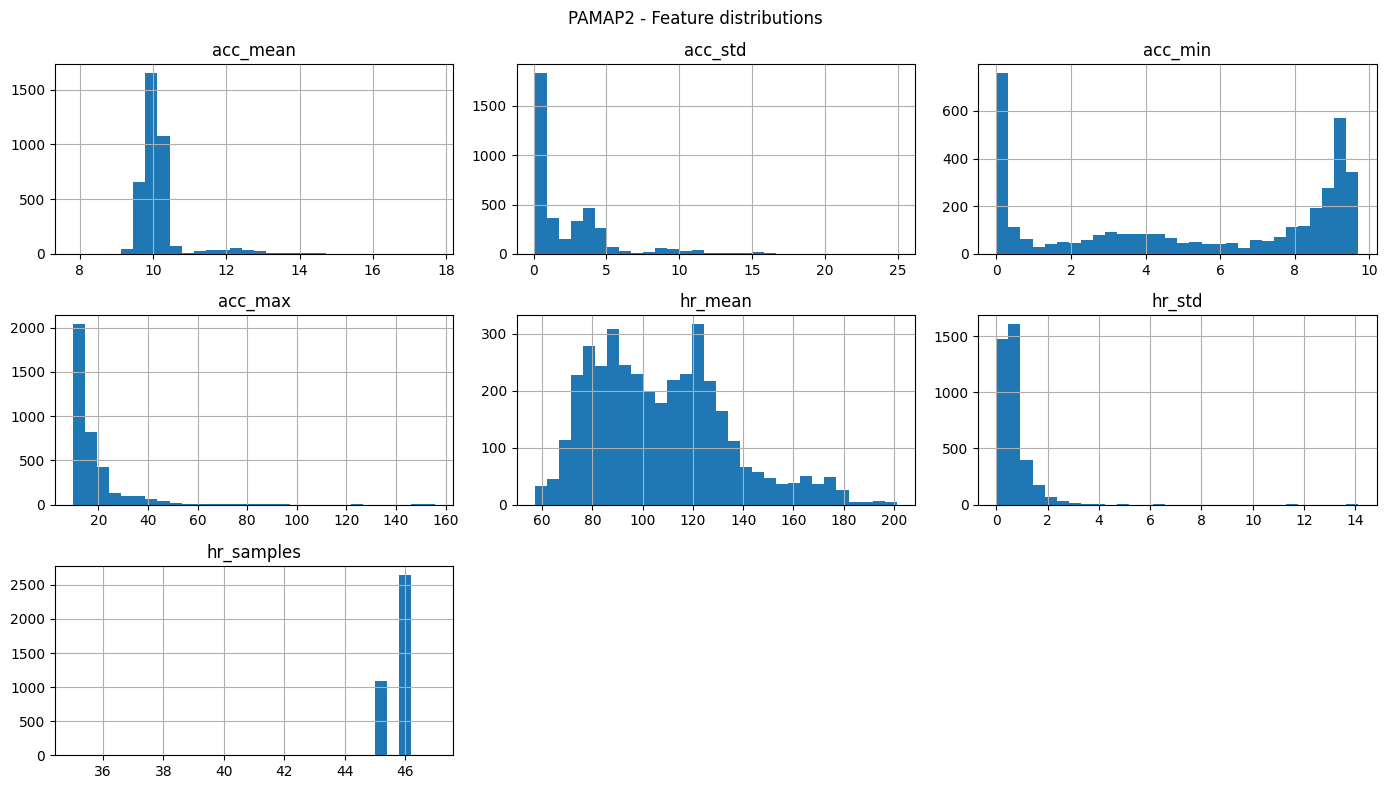

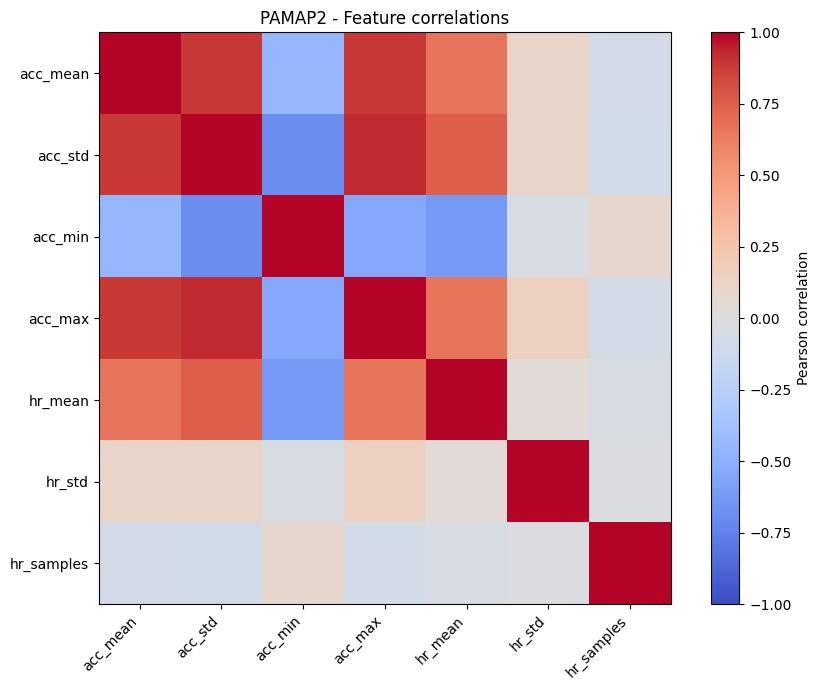


===== MHEALTH =====

Descriptive statistics:


,acc_mean,acc_std,acc_min,acc_max,ecg_mean,ecg_std,ecg_min,ecg_max
count,1251.000,1251.000,1251.000,1251.000,1251.000,1251.000,1251.000,1251.000
mean,10.066,2.550,6.074,16.131,0.003,0.596,-1.333,2.633
std,0.733,3.108,3.131,7.138,0.386,0.455,1.254,1.222
min,8.974,0.107,0.108,9.952,-4.227,0.128,-8.620,-0.507
25%,9.695,0.187,4.455,10.400,-0.045,0.377,-1.440,1.599
50%,9.785,1.357,6.646,13.671,-0.005,0.501,-0.992,2.667
75%,9.944,2.560,9.057,17.367,0.051,0.661,-0.661,3.326
max,13.137,10.284,9.705,36.013,2.780,4.469,1.168,8.506



Feature correlations:


,acc_mean,acc_std,acc_min,acc_max,ecg_mean,ecg_std,ecg_min,ecg_max
acc_mean,1.000,0.858,-0.745,0.842,-0.114,0.448,-0.479,0.305
acc_std,0.858,1.000,-0.948,0.979,-0.066,0.469,-0.503,0.323
acc_min,-0.745,-0.948,1.000,-0.936,0.035,-0.467,0.503,-0.299
acc_max,0.842,0.979,-0.936,1.000,-0.060,0.482,-0.512,0.332
ecg_mean,-0.114,-0.066,0.035,-0.060,1.000,-0.184,0.369,0.084
ecg_std,0.448,0.469,-0.467,0.482,-0.184,1.000,-0.883,0.767
ecg_min,-0.479,-0.503,0.503,-0.512,0.369,-0.883,1.000,-0.502
ecg_max,0.305,0.323,-0.299,0.332,0.084,0.767,-0.502,1.000


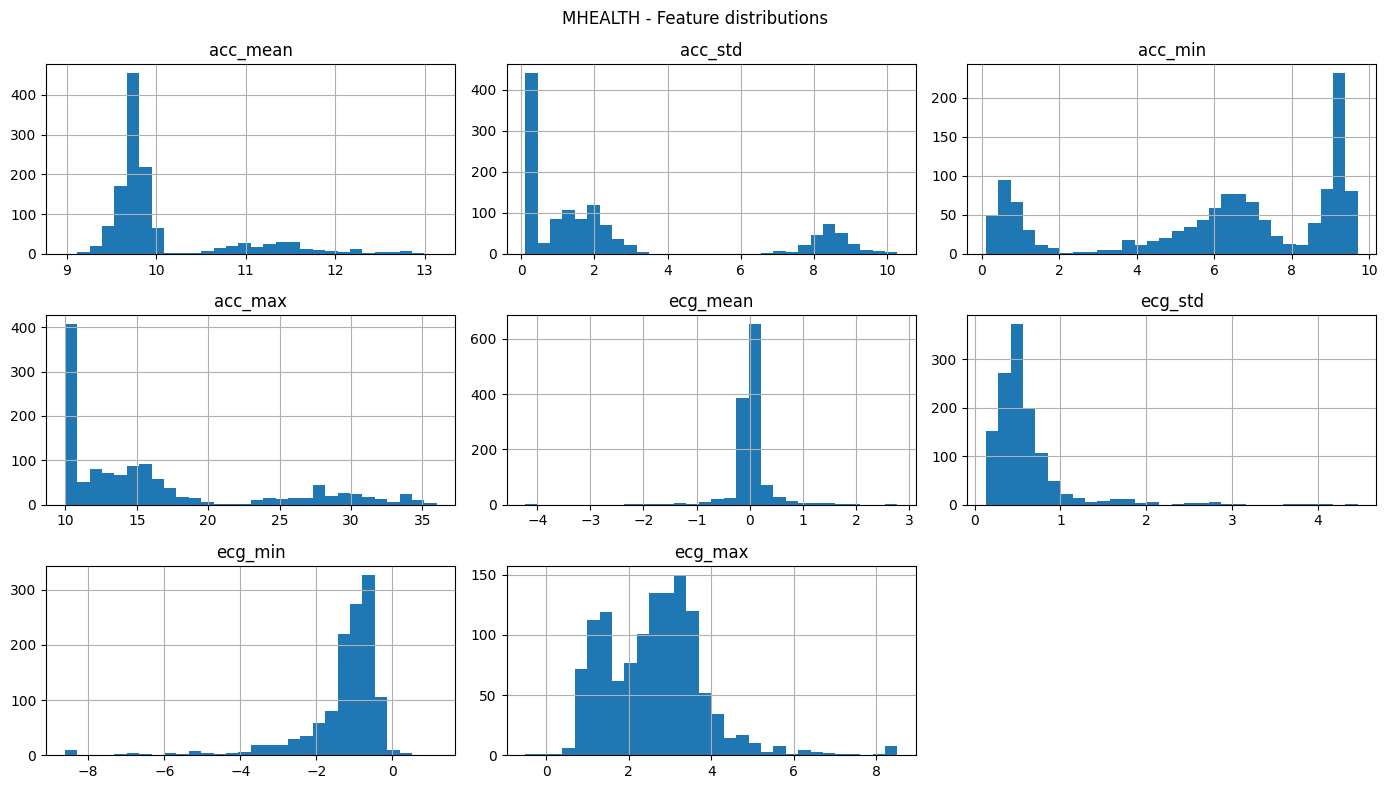

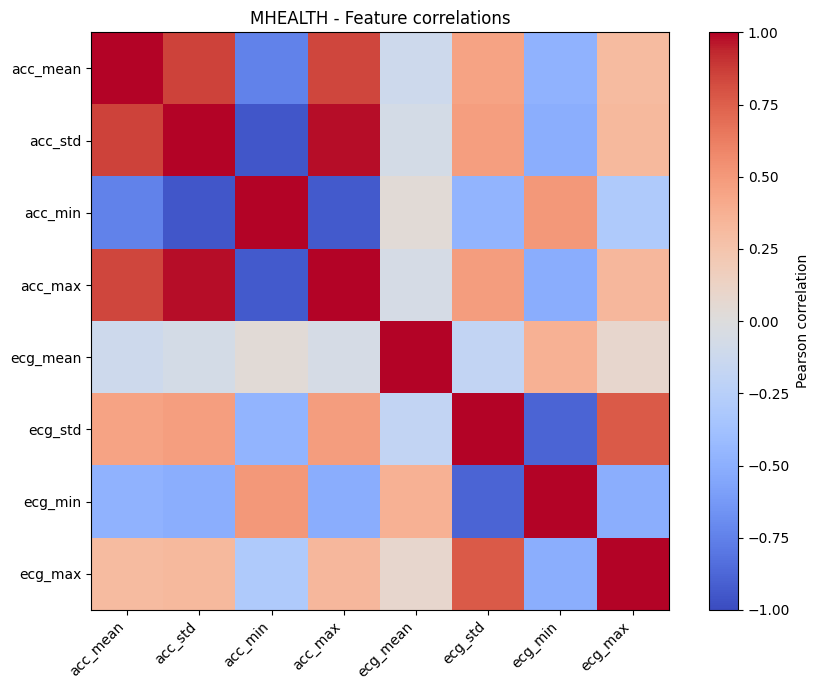


===== CROSS-MODAL CORRELATIONS =====

PAMAP2: ACC vs cardiac


,hr_mean,hr_std
acc_mean,0.667,0.102
acc_std,0.754,0.103
acc_min,-0.619,-0.043
acc_max,0.661,0.134



MHEALTH: ACC vs cardiac


,ecg_mean,ecg_std,ecg_min,ecg_max
acc_mean,-0.114,0.448,-0.479,0.305
acc_std,-0.066,0.469,-0.503,0.323
acc_min,0.035,-0.467,0.503,-0.299
acc_max,-0.060,0.482,-0.512,0.332


In [26]:

# CP2 - Descriptive statistics and cross-modal correlations

import pandas as pd
import matplotlib.pyplot as plt

datasets = {
    "PAMAP2": pamap2_X,
    "MHEALTH": mhealth_X
}

for name, X in datasets.items():
    print(f"\n===== {name} =====")

    # Exclude IDs and activity labels from feature statistics
    feature_cols = [
        c for c in X.columns
        if c not in ["subject_id", "window_id", "activity"]
    ]

    print("\nDescriptive statistics:")
    display(
        X[feature_cols]
        .describe()
        .round(3)
    )

    print("\nFeature correlations:")
    corr = X[feature_cols].corr()
    display(corr.round(3))

    # Plot feature distributions
    X[feature_cols].hist(
        bins=30,
        figsize=(14, 8)
    )
    plt.suptitle(f"{name} - Feature distributions")
    plt.tight_layout()
    plt.show()

    # Correlation heatmap
    plt.figure(figsize=(9, 7))
    plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar(label="Pearson correlation")
    plt.xticks(
        range(len(feature_cols)),
        feature_cols,
        rotation=45,
        ha="right"
    )
    plt.yticks(range(len(feature_cols)), feature_cols)
    plt.title(f"{name} - Feature correlations")
    plt.tight_layout()
    plt.show()

# Cross-modal correlations: motion vs cardiac
print("\n===== CROSS-MODAL CORRELATIONS =====")

for name, X in datasets.items():
    acc_cols = [c for c in X.columns if c.startswith("acc_")]
    cardiac_prefix = "hr_" if name == "PAMAP2" else "ecg_"
    cardiac_cols = [
        c for c in X.columns
        if c.startswith(cardiac_prefix)
        and c != "hr_samples"
    ]

    cross_corr = X[acc_cols + cardiac_cols].corr().loc[
        acc_cols, cardiac_cols
    ]

    print(f"\n{name}: ACC vs cardiac")
    display(cross_corr.round(3))


In [28]:
# Find existing feature matrices
[name for name in globals() if "feature" in name.lower() or "matrix" in name.lower()]

['pamap2_features_data', 'mhealth_features_data', 'feature_cols']

In [31]:

for name, df in {
    "PAMAP2": pamap2_features_data,
    "MHEALTH": mhealth_features_data
}.items():
    print(f"\n===== {name} =====")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))



===== PAMAP2 =====
Shape: (1891500, 57)
Columns: ['timestamp', 'activity_id', 'heart_rate', 'hand_temperature', 'hand_acc16_x', 'hand_acc16_y', 'hand_acc16_z', 'hand_acc6_x', 'hand_acc6_y', 'hand_acc6_z', 'hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z', 'hand_mag_x', 'hand_mag_y', 'hand_mag_z', 'hand_orientation_1', 'hand_orientation_2', 'hand_orientation_3', 'hand_orientation_4', 'chest_temperature', 'chest_acc16_x', 'chest_acc16_y', 'chest_acc16_z', 'chest_acc6_x', 'chest_acc6_y', 'chest_acc6_z', 'chest_gyro_x', 'chest_gyro_y', 'chest_gyro_z', 'chest_mag_x', 'chest_mag_y', 'chest_mag_z', 'chest_orientation_1', 'chest_orientation_2', 'chest_orientation_3', 'chest_orientation_4', 'ankle_temperature', 'ankle_acc16_x', 'ankle_acc16_y', 'ankle_acc16_z', 'ankle_acc6_x', 'ankle_acc6_y', 'ankle_acc6_z', 'ankle_gyro_x', 'ankle_gyro_y', 'ankle_gyro_z', 'ankle_mag_x', 'ankle_mag_y', 'ankle_mag_z', 'ankle_orientation_1', 'ankle_orientation_2', 'ankle_orientation_3', 'ankle_orientation_4', 'subject_

,timestamp,activity_id,heart_rate,hand_temperature,hand_acc16_x,hand_acc16_y,hand_acc16_z,hand_acc6_x,hand_acc6_y,hand_acc6_z,...,ankle_mag_x,ankle_mag_y,ankle_mag_z,ankle_orientation_1,ankle_orientation_2,ankle_orientation_3,ankle_orientation_4,subject_id,window_id,acc_magnitude
0,40.00,1,102.0,30.4375,-0.267412,8.28172,3.70294,-0.160122,7.64797,3.60136,...,-57.6760,-41.9467,-58.5757,1.0,0.0,0.0,0.0,101,8,10.155807
1,40.01,1,NaN,30.4375,-0.615278,8.50964,3.42755,-0.319057,8.25341,3.81161,...,-57.6862,-41.4986,-59.0659,1.0,0.0,0.0,0.0,101,8,9.854157
2,40.02,1,NaN,30.4375,-1.019470,9.00807,3.65073,-0.707337,8.66399,3.82621,...,-58.5862,-41.2463,-59.0559,1.0,0.0,0.0,0.0,101,8,9.701537



===== MHEALTH =====
Shape: (312750, 28)
Columns: ['chest_acc_x', 'chest_acc_y', 'chest_acc_z', 'ecg_lead_1', 'ecg_lead_2', 'ankle_acc_x', 'ankle_acc_y', 'ankle_acc_z', 'ankle_gyro_x', 'ankle_gyro_y', 'ankle_gyro_z', 'ankle_mag_x', 'ankle_mag_y', 'ankle_mag_z', 'arm_acc_x', 'arm_acc_y', 'arm_acc_z', 'arm_gyro_x', 'arm_gyro_y', 'arm_gyro_z', 'arm_mag_x', 'arm_mag_y', 'arm_mag_z', 'activity', 'subject_id', 'sample_id', 'window_id', 'acc_magnitude']


,chest_acc_x,chest_acc_y,chest_acc_z,ecg_lead_1,ecg_lead_2,ankle_acc_x,ankle_acc_y,ankle_acc_z,ankle_gyro_x,ankle_gyro_y,...,arm_gyro_y,arm_gyro_z,arm_mag_x,arm_mag_y,arm_mag_z,activity,subject_id,sample_id,window_id,acc_magnitude
0,-9.9356,0.31502,0.98625,0.217690,-0.20931,2.2119,-9.5303,0.43102,-0.20779,-0.87992,...,-0.94867,-0.34052,0.72714,0.90023,0.005541,1,1,6750,27,9.989398
1,-9.5076,0.12598,1.12710,-0.104660,-0.21769,2.4295,-9.7570,0.53644,-0.20223,-0.87242,...,-0.94867,-0.34052,0.36803,0.89652,-0.723630,1,1,6751,27,9.575003
2,-9.8110,0.14639,0.80265,-0.066981,-0.12559,2.4050,-9.5611,0.32725,-0.20223,-0.87242,...,-0.94867,-0.34052,0.36803,0.89652,-0.723630,1,1,6752,27,9.844867


In [32]:

import pandas as pd

for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        columns = set(value.columns)

        if {"acc_mean", "acc_std"}.issubset(columns):
            print(
                f"{name}: {value.shape} | "
                f"columns: {value.columns.tolist()}"
            )


pamap2_X: (3783, 10) | columns: ['subject_id', 'window_id', 'activity', 'acc_mean', 'acc_std', 'acc_min', 'acc_max', 'hr_mean', 'hr_std', 'hr_samples']
mhealth_X: (1251, 11) | columns: ['subject_id', 'window_id', 'activity', 'acc_mean', 'acc_std', 'acc_min', 'acc_max', 'ecg_mean', 'ecg_std', 'ecg_min', 'ecg_max']
corr: (8, 8) | columns: ['acc_mean', 'acc_std', 'acc_min', 'acc_max', 'ecg_mean', 'ecg_std', 'ecg_min', 'ecg_max']



===== PAMAP2 =====
Observations: 3783
Features: 6
Missing values: 0
PC1 variance: 64.57 %
PC2 variance: 16.64 %
PC1 + PC2: 81.21 %
Components for 90% variance: 3

Loadings:


,PC1,PC2
acc_mean,0.457,0.028
acc_std,0.495,-0.015
acc_min,-0.372,0.123
acc_max,0.471,0.049
hr_mean,0.425,-0.114
hr_std,0.067,0.984


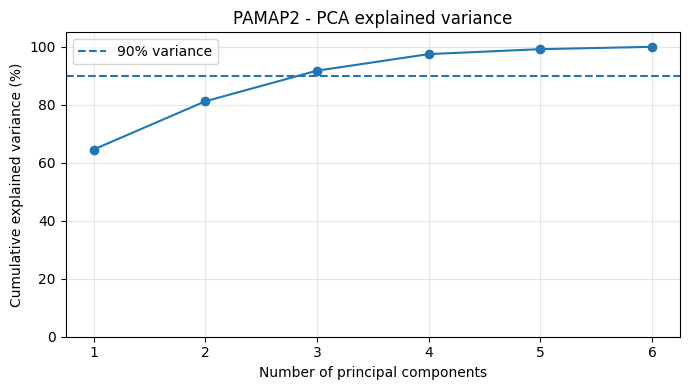


===== MHEALTH =====
Observations: 1251
Features: 8
Missing values: 0
PC1 variance: 58.63 %
PC2 variance: 18.68 %
PC1 + PC2: 77.32 %
Components for 90% variance: 3

Loadings:


,PC1,PC2
acc_mean,0.390,-0.237
acc_std,0.425,-0.298
acc_min,-0.410,0.285
acc_max,0.425,-0.284
ecg_mean,-0.077,-0.273
ecg_std,0.350,0.495
ecg_min,-0.350,-0.420
ecg_max,0.260,0.443


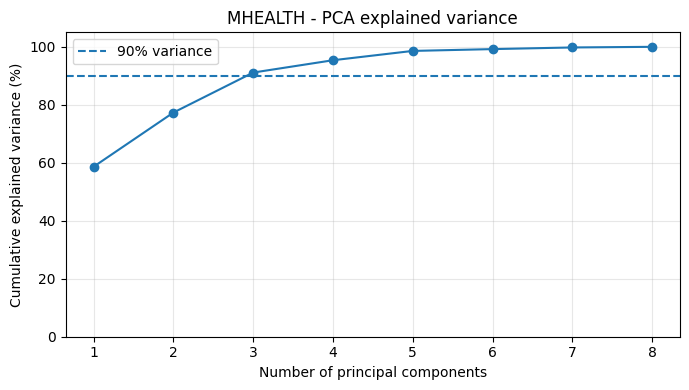

In [33]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

datasets = {
    "PAMAP2": (
        pamap2_X,
        ["acc_mean", "acc_std", "acc_min", "acc_max",
         "hr_mean", "hr_std"]
    ),
    "MHEALTH": (
        mhealth_X,
        ["acc_mean", "acc_std", "acc_min", "acc_max",
         "ecg_mean", "ecg_std", "ecg_min", "ecg_max"]
    )
}

pca_results = {}

for name, (df, features) in datasets.items():

    print(f"\n===== {name} =====")

    X = df[features].copy()
    X = X.replace([np.inf, -np.inf], np.nan)

    print("Observations:", len(X))
    print("Features:", len(features))
    print("Missing values:", X.isna().sum().sum())

    if X.isna().any().any():
        raise ValueError(
            f"{name}: missing values in PCA features"
        )

    # Standardization
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)

    explained = pca.explained_variance_ratio_
    cumulative = np.cumsum(explained)

    loadings = pd.DataFrame(
        pca.components_.T,
        index=features,
        columns=[
            f"PC{i+1}" for i in range(len(features))
        ]
    )

    pca_results[name] = {
        "scaler": scaler,
        "pca": pca,
        "transformed": X_pca,
        "loadings": loadings,
        "cumulative_variance": cumulative
    }

    print(
        "PC1 variance:",
        round(explained[0] * 100, 2), "%"
    )

    print(
        "PC2 variance:",
        round(explained[1] * 100, 2), "%"
    )

    print(
        "PC1 + PC2:",
        round(cumulative[1] * 100, 2), "%"
    )

    print(
        "Components for 90% variance:",
        np.searchsorted(cumulative, 0.90) + 1
    )

    print("\nLoadings:")
    display(loadings[["PC1", "PC2"]].round(3))

    plt.figure(figsize=(7, 4))
    plt.plot(
        range(1, len(cumulative) + 1),
        cumulative * 100,
        marker="o"
    )
    plt.axhline(
        90,
        linestyle="--",
        label="90% variance"
    )
    plt.xlabel("Number of principal components")
    plt.ylabel("Cumulative explained variance (%)")
    plt.title(f"{name} - PCA explained variance")
    plt.xticks(range(1, len(cumulative) + 1))
    plt.ylim(0, 105)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [34]:

# ============================================================
# CP2 - SUBJECT-WISE PROTOCOL
# ACC-only vs ACC + cardiac
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

feature_sets = {
    "PAMAP2": {
        "ACC-only": [
            "acc_mean", "acc_std", "acc_min", "acc_max"
        ],
        "ACC + HR": [
            "acc_mean", "acc_std", "acc_min", "acc_max",
            "hr_mean", "hr_std"
        ]
    },
    "MHEALTH": {
        "ACC-only": [
            "acc_mean", "acc_std", "acc_min", "acc_max"
        ],
        "ACC + ECG": [
            "acc_mean", "acc_std", "acc_min", "acc_max",
            "ecg_mean", "ecg_std", "ecg_min", "ecg_max"
        ]
    }
}

matrices = {
    "PAMAP2": pamap2_X,
    "MHEALTH": mhealth_X
}

protocol_results = []
protocol_data = {}

for dataset_name, df in matrices.items():

    print(f"\n===== {dataset_name} =====")

    # One split per dataset, shared by both configurations
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.2,
        random_state=42
    )

    train_idx, test_idx = next(
        splitter.split(
            df,
            groups=df["subject_id"]
        )
    )

    train_subjects = set(
        df.iloc[train_idx]["subject_id"]
    )
    test_subjects = set(
        df.iloc[test_idx]["subject_id"]
    )

    assert train_subjects.isdisjoint(test_subjects)

    print("Train subjects:", sorted(train_subjects))
    print("Test subjects:", sorted(test_subjects))

    for configuration, columns in feature_sets[
        dataset_name
    ].items():

        X = df[columns].copy()
        X = X.replace([np.inf, -np.inf], np.nan)

        if X.isna().any().any():
            raise ValueError(
                f"{dataset_name} / {configuration}: "
                "missing values detected"
            )

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        pca = PCA()

        train_pca = pca.fit_transform(
            X_train_scaled
        )

        test_pca = pca.transform(
            X_test_scaled
        )

        cumulative = np.cumsum(
            pca.explained_variance_ratio_
        )

        n90 = (
            np.searchsorted(cumulative, 0.90) + 1
        )

        protocol_results.append({
            "Dataset": dataset_name,
            "Configuration": configuration,
            "Train subjects": len(train_subjects),
            "Test subjects": len(test_subjects),
            "Train windows": len(train_idx),
            "Test windows": len(test_idx),
            "Features": len(columns),
            "PC1 (%)": round(
                pca.explained_variance_ratio_[0] * 100, 2
            ),
            "PC1+PC2 (%)": round(
                cumulative[1] * 100, 2
            ),
            "PCs for 90%": int(n90)
        })

        protocol_data[
            (dataset_name, configuration)
        ] = {
            "scaler": scaler,
            "pca": pca,
            "train_indices": train_idx,
            "test_indices": test_idx,
            "train_pca": train_pca,
            "test_pca": test_pca,
            "features": columns
        }

results_df = pd.DataFrame(protocol_results)

print("\n===== CP2 COMPARISON =====")
display(results_df)



===== PAMAP2 =====
Train subjects: ['101', '103', '104', '105', '106', '107', '109']
Test subjects: ['102', '108']

===== MHEALTH =====
Train subjects: ['1', '2', '3', '4', '5', '6', '7', '9']
Test subjects: ['10', '8']

===== CP2 COMPARISON =====


,Dataset,Configuration,Train subjects,Test subjects,Train windows,Test windows,Features,PC1 (%),PC1+PC2 (%),PCs for 90%
0,PAMAP2,ACC-only,7,2,2762,1021,4,81.27,95.89,2
1,PAMAP2,ACC + HR,7,2,2762,1021,6,64.92,81.61,3
2,MHEALTH,ACC-only,8,2,1006,245,4,91.23,98.27,1
3,MHEALTH,ACC + ECG,8,2,1006,245,8,55.85,75.23,4


In [35]:

import inspect
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("=== CP2: PCA protocol verification ===")

for name in ["pamap2_X", "mhealth_X",
             "pamap2_features_data", "mhealth_features_data"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {obj.shape}")

print("\nExisting scaler/PCA objects:")
for name, obj in list(globals().items()):
    if isinstance(obj, (StandardScaler, PCA)):
        print(name, type(obj).__name__)

print("\nExisting split-related variables:")
for name in sorted(globals()):
    if any(term in name.lower() for term in
           ["train_idx", "test_idx", "train_subject",
            "test_subject", "protocol_results"]):
        print(name)


=== CP2: PCA protocol verification ===
pamap2_X: (3783, 10)
mhealth_X: (1251, 11)
pamap2_features_data: (1891500, 57)
mhealth_features_data: (312750, 28)

Existing scaler/PCA objects:
scaler StandardScaler
pca PCA

Existing split-related variables:
protocol_results
test_idx
test_subjects
train_idx
train_subjects


In [36]:

import inspect
from IPython.display import display

print("=== CP2: Existing protocol ===")

print("\nProtocol results:")
if "protocol_results" in globals():
    display(pd.DataFrame(protocol_results))

print("\nTrain/test index types:")
for name in ["train_idx", "test_idx"]:
    if name in globals():
        obj = globals()[name]
        print(name, type(obj).__name__, "length:", len(obj))

print("\nScaler:")
print("Fitted:", hasattr(scaler, "mean_"))
if hasattr(scaler, "n_samples_seen_"):
    print("Samples used for fitting:", scaler.n_samples_seen_)

print("\nPCA:")
print("Fitted:", hasattr(pca, "components_"))
if hasattr(pca, "n_samples_"):
    print("Samples used for fitting:", pca.n_samples_)


=== CP2: Existing protocol ===

Protocol results:


,Dataset,Configuration,Train subjects,Test subjects,Train windows,Test windows,Features,PC1 (%),PC1+PC2 (%),PCs for 90%
0,PAMAP2,ACC-only,7,2,2762,1021,4,81.27,95.89,2
1,PAMAP2,ACC + HR,7,2,2762,1021,6,64.92,81.61,3
2,MHEALTH,ACC-only,8,2,1006,245,4,91.23,98.27,1
3,MHEALTH,ACC + ECG,8,2,1006,245,8,55.85,75.23,4



Train/test index types:
train_idx ndarray length: 1006
test_idx ndarray length: 245

Scaler:
Fitted: True
Samples used for fitting: 1006

PCA:
Fitted: True
Samples used for fitting: 1006
